# 01 · Preprocessing — Rendeiro 2020 CLL (malignant compartment)

Isolate malignant cells, threshold thin samples, integrate patients (Harmony), embed, remove
detached islands, resolve the manifold's transcriptional compartments, and fix a single house
orientation for every downstream UMAP. Rendeiro et al. (2020) profiled peripheral-blood CLL
(chronic lymphocytic leukemia) by **10x** across four patients (CLL1/5/6/8) sampled longitudinally
before and during ibrutinib therapy (d0…d280). Its malignant B cells form a single dominant body;
whether the gastrulation / somitogenesis / neural-crest developmental axis resolves into competing
arms (Puram) or collapses onto one gradient (Kürten / Bischoff / Sun / Lee / Olalekan) is **derived
in 02 from the signature geography**, not assumed here. CLL is a proliferative leukemia, so the
cell-cycle confound (Kürten lobe-identity fork) is checked explicitly. Every tunable choice is
*derived from this dataset*, not inherited. Deliverable: `processed.h5ad`, `samples.pdf`.

In [1]:
import os, sys, glob
os.environ['R_HOME'] = sys.exec_prefix + '/lib/R/'
import numpy as np, pandas as pd
import scanpy as sc, scanpy.external as sce, scFates as scf
import matplotlib.pyplot as plt
sc.settings.verbosity = 1
SEED = 1; np.random.seed(SEED)

In [2]:
# cwd = <root>/mesencontext/claude/<Category>/<Dataset>
name = os.path.basename(os.getcwd())                    # dataset (folder minus 'Data_')
cat  = os.path.basename(os.path.dirname(os.getcwd()))   # Category partition
pth  = os.path.join(*([os.pardir]*4))                   # -> EMToolbox root
pth_data = os.path.join(pth, 'data')
sys.path.append(os.path.join(pth, 'mesencontext'))
from scripts.load import load_CCCA_adata

pth_in  = os.path.join(pth_data, 'unzip', 'CCCA', 'Data_' + name)        # raw input
pth_out = os.path.join(pth_data, 'cancer', 'vertebrate', 'CCCA', 'claude', cat, name)  # h5ads
pth_fig = os.path.join(pth, 'figures', 'mesencontext', 'claude', cat, name)
pth_cb  = os.path.join(pth_fig, 'colorbars')
os.makedirs(pth_out, exist_ok=True); os.makedirs(pth_cb, exist_ok=True)
print('dataset:', name, '| category:', cat)

dataset: Rendeiro2020_Hematologic | category: Hematologic


### Load malignant compartment
Rendeiro et al. supply a per-cell `cell_type` annotation in which **Malignant** is an explicit
label (the publication's CLL-cell call); the loader exposes it as `celltype`, taken directly (per
protocol: use the publication's calls). 10x UMI counts are `normalize_total`- then
`log1p`-transformed by the loader.

In [3]:
adata = load_CCCA_adata(pth_in)
print('full atlas:', adata.shape)
adata = adata[adata.obs['celltype'] == 'Malignant'].copy()
print('malignant:', adata.shape, '| samples:', adata.obs['sample'].nunique(),
      '| patients:', adata.obs['patient'].nunique())
print('expression: X max %.2f (log1p of normalize_total UMI counts)' % adata.X.max())

Loading ../../../../../../data/unzip/CCCA/Data_Rendeiro2020_Hematologic
Done.
full atlas: (48016, 18402)
malignant: (18854, 18402) | samples: 11 | patients: 4
expression: X max 6.35 (log1p of normalize_total UMI counts)


### Sample thresholding — multiplicative gap-finding, with a floor fallback
Per protocol we look for the largest **multiplicative** cliff in the sorted per-sample counts (the
natural separatrix between tumour-bearing samples and spillover). Here the sorted counts fall
1012→80 — a **12.6× cliff**, dominant over the runner-up (2.3× ratio-of-ratios ≥ 1.5) and dropping
below the 2×floor guard — a genuine spillover cliff (the C3 clean-gap premise *is* met). The
geometric-mean threshold (√(1012·80) ≈ 284) keeps the **7 well-populated longitudinal samples**
(1012–5074 malignant cells) spanning all four patients and drops the four thin spillover samples
(80/78/33/6).

In [4]:
n = adata.obs['sample'].value_counts()
vals = n.values.astype(float)
ratios = vals[:-1] / vals[1:]
gap = int(np.argmax(ratios))
srt = np.sort(ratios)[::-1]
top, second = srt[0], srt[1]
FLOOR = 100
dominant = (top/second >= 1.5) and (vals[gap+1] < 2*FLOOR)   # a real spillover cliff?
print('sorted per-sample counts:', dict(zip(n.index, n.values.astype(int))))
print('gap ratios:', [f'{int(vals[i])}->{int(vals[i+1])}:{ratios[i]:.2f}' for i in range(len(ratios))])
print(f'argmax gap {int(vals[gap])}->{int(vals[gap+1])} (ratio {top:.2f}); top/second = {top/second:.2f}; dominant cliff = {dominant}')
if dominant:
    thresh = int(np.sqrt(vals[gap]*vals[gap+1]))
    print(f'dominant spillover cliff -> geometric-mean threshold = {thresh}')
else:
    thresh = FLOOR
    print(f'no dominant cliff -> floor >= {FLOOR}')
keep = n.index[n >= thresh]
adata = adata[adata.obs['sample'].isin(keep)].copy()
print(f'kept {len(keep)}/{len(n)} samples (min per-sample = {int(n[n>=thresh].min())}) -> {adata.shape[0]} cells')
print('patients retained:', sorted(adata.obs['patient'].unique()))

sorted per-sample counts: {'CLL5_d0': np.int64(5074), 'CLL6_d30': np.int64(4353), 'CLL5_d30': np.int64(2818), 'CLL1_d0': np.int64(2267), 'CLL6_d120': np.int64(1575), 'CLL8_d0': np.int64(1558), 'CLL6_d0': np.int64(1012), 'CLL5_d150': np.int64(80), 'CLL8_d30': np.int64(78), 'CLL6_d280': np.int64(33), 'CLL1_d120': np.int64(6)}
gap ratios: ['5074->4353:1.17', '4353->2818:1.54', '2818->2267:1.24', '2267->1575:1.44', '1575->1558:1.01', '1558->1012:1.54', '1012->80:12.65', '80->78:1.03', '78->33:2.36', '33->6:5.50']
argmax gap 1012->80 (ratio 12.65); top/second = 2.30; dominant cliff = True
dominant spillover cliff -> geometric-mean threshold = 284
kept 7/11 samples (min per-sample = 1012) -> 18657 cells
patients retained: ['CLL1', 'CLL5', 'CLL6', 'CLL8']


### Cell cycle (de-novo — publication ships no phase calls)
Rendeiro's metadata has no cell-cycle annotation, so we score it with the Tirosh S / G2M gene lists
(`score_genes_cell_cycle`) and map to the house `cell_cycle_phase` labels. CLL is a circulating
leukemia with a substantial proliferative fraction; quantifying it now lets the proliferation
confound be checked against the developmental modules in 02 (biology before geometry).

In [5]:
s_genes = ('MCM5 PCNA TYMS FEN1 MCM2 MCM4 RRM1 UNG GINS2 MCM6 CDCA7 DTL PRIM1 UHRF1 HELLS RFC2 RPA2 '
    'NASP RAD51AP1 GMNN WDR76 SLBP CCNE2 UBR7 POLD3 MSH2 ATAD2 RAD51 RRM2 CDC45 CDC6 EXO1 TIPIN DSCC1 '
    'BLM CASP8AP2 USP1 CLSPN POLA1 CHAF1B BRIP1 E2F8').split()
g2m_genes = ('HMGB2 CDK1 NUSAP1 UBE2C BIRC5 TPX2 TOP2A NDC80 CKS2 NUF2 CKS1B MKI67 TMPO CENPF TACC3 '
    'FAM64A SMC4 CCNB2 CKAP2L CKAP2 AURKB BUB1 KIF11 ANP32E TUBB4B GTSE1 KIF20B HJURP CDCA3 HN1 CDC20 TTK '
    'CDC25C KIF2C RANGAP1 NCAPD2 DLGAP5 CDCA2 CDCA8 ECT2 KIF23 HMMR AURKA PSRC1 ANLN LBR CKAP5 CENPE CTCF '
    'NEK2 G2E3 GAS2L3 CBX5 CENPA').split()
sg = [g for g in s_genes if g in adata.var_names]; gg = [g for g in g2m_genes if g in adata.var_names]
sc.tl.score_genes_cell_cycle(adata, s_genes=sg, g2m_genes=gg)
adata.obs['cell_cycle_phase'] = adata.obs['phase'].map({'S':'G1/S','G2M':'G2/M','G1':'G1'}).astype(str)
adata.obs['g1s_score'] = adata.obs['S_score']; adata.obs['g2m_score'] = adata.obs['G2M_score']
adata.obs['cycling'] = adata.obs['cell_cycle_phase'].isin(['G1/S','G2/M','Intermediate'])
print('cell-cycle genes present: S=%d/43, G2M=%d/54' % (len(sg), len(gg)))
print('phase counts:', adata.obs['cell_cycle_phase'].value_counts().to_dict())
print('cycling fraction: %.3f (CLL is a proliferative leukemia)' % adata.obs['cycling'].mean())

cell-cycle genes present: S=42/43, G2M=52/54
phase counts: {'G1': 10488, 'G1/S': 7376, 'G2/M': 793}
cycling fraction: 0.438 (CLL is a proliferative leukemia)


### Overdispersion, PCA, Harmony integration, embedding
`theta` is selected by a same-sample-neighbour-fraction sweep (lower = better mixing): mixing
improves sharply from theta=2 (0.38) to theta=5 (0.24) and then flattens (theta=10 ≈ 0.22, within
noise of theta=5), so the mixing floor is already reached. CLL malignant cells carry strong
patient-private CNV/BCR states, so we take the strongest integration on the plateau (theta=10) to
suppress the batch effect without collapsing biological structure. PC count (20) and UMAP spread
(1.3) follow the comparable-scale 10x precedents (Kürten / Sun / Lee / Steele / Qian / Olalekan).

In [6]:
sc.pp.filter_genes(adata, min_cells=3)
scf.pp.find_overdispersed(adata)
print('overdispersed genes:', int(adata.var.highly_variable.sum()))
sc.pp.pca(adata, n_comps=50)

from sklearn.neighbors import NearestNeighbors as _NN
def _same_sample_frac(rep):
    idx = _NN(n_neighbors=31).fit(rep).kneighbors(rep, return_distance=False)[:,1:]
    s = adata.obs['sample'].values
    return float(np.mean([ (s[idx[i]]==s[i]).mean() for i in range(len(s)) ]))
base = _same_sample_frac(adata.obsm['X_pca'][:,:20])
sweep = {}
for th in [2, 5, 10]:
    sce.pp.harmony_integrate(adata, 'sample', theta=th, max_iter_harmony=30, random_state=SEED)
    sweep[th] = _same_sample_frac(adata.obsm['X_pca_harmony'][:,:20])
print('same-sample neighbour fraction | pre-Harmony %.3f' % base,
      '| sweep', {k: round(v,3) for k,v in sweep.items()})
theta = 10
print('selected theta =', theta,
      '(mixing improves sharply to theta=5 then flattens - theta=10 within noise of theta=5;',
      'strongest integration chosen for the strong patient-private CLL batch effect, without collapsing structure)')
sce.pp.harmony_integrate(adata, 'sample', theta=theta, max_iter_harmony=30, random_state=SEED)
sc.pp.neighbors(adata, n_pcs=20, use_rep='X_pca_harmony', n_neighbors=30, random_state=SEED)
sc.tl.umap(adata, spread=1.3, random_state=SEED)

Finding overdispersed features
    computing mean and variances
    gam fitting
    found 528 over-dispersed features (0:00:01) --> added 
    .var['res'], residuals of GAM fit.
    .var['lp'], p-value.
    .var['lpa'], BH adjusted p-value.
    .var['qv'], percentile of qui-squared distribution.
    .var['highly_variable'], feature is over-dispersed.

overdispersed genes: 528
same-sample neighbour fraction | pre-Harmony 0.965 | sweep {2: 0.383, 5: 0.239, 10: 0.223}
selected theta = 10 (mixing improves sharply to theta=5 then flattens - theta=10 within noise of theta=5; strongest integration chosen for the strong patient-private CLL batch effect, without collapsing structure)


### Remove detached islands (data-driven)
Build a radius graph on the UMAP (6× the median nearest-neighbour distance) and drop any cell
outside the main connected component — stripping physically detached specks while keeping the
continuous manifold body. Here three tiny specks (205 cells) detach and are removed; the retained
manifold is a single connected component.

In [7]:
from sklearn.neighbors import NearestNeighbors
from scipy.sparse.csgraph import connected_components
um = adata.obsm['X_umap']
d,_ = NearestNeighbors(n_neighbors=6).fit(um).kneighbors(um)
adj = NearestNeighbors(radius=6*np.median(d[:,1:])).fit(um).radius_neighbors_graph(um)
ncomp, lab = connected_components(adj, directed=False)
main = pd.Series(lab).value_counts().index[0]
print('component sizes:', pd.Series(lab).value_counts().values[:6])
print('removed', int((lab!=main).sum()), 'cells in', ncomp-1, 'detached islands')
adata = adata[lab==main].copy()
sc.pp.neighbors(adata, n_pcs=20, use_rep='X_pca_harmony', n_neighbors=30, random_state=SEED)
sc.tl.umap(adata, spread=1.3, random_state=SEED)
print('after island removal:', adata.shape[0], 'cells on one connected component')

component sizes: [18452   203     1     1]
removed 205 cells in 3 detached islands
after island removal: 18452 cells on one connected component


### Compartment split + cell-cycle confound check (data-driven)
Low-resolution Leiden (res=0.15) probes for separable lobes. CLL's malignant manifold is a **single
lobe** at res=0.15 — there is no discrete proliferative compartment even though ~44% of cells are
cycling: proliferation is *diffuse* across the manifold rather than segregated. Critically, the
developmental modules (scored here for the check) are **not confounded by cycling** — each module's
smoothed score correlates near-zero with the cycling score — so the whole manifold is a valid
developmental object and is carried forward (the Kürten cycling-lobe scoping does not arise here).

In [8]:
import scipy.sparse as sp
sc.tl.leiden(adata, resolution=0.15, key_added='lobe', random_state=SEED,
             flavor='igraph', n_iterations=2, directed=False)
prolif = [g for g in ['MKI67','UBE2C','STMN1','TOP2A','CDK1','TYMS','PCNA'] if g in adata.var_names]
sc.tl.score_genes(adata, prolif, score_name='prolif_score', random_state=SEED)
print('lobe sizes (res=0.15):', adata.obs['lobe'].value_counts().to_dict())
print('overall cycling fraction: %.3f' % adata.obs['cycling'].mean())
print('cycling fraction per lobe:', adata.obs.groupby('lobe', observed=True)['cycling'].mean().round(3).to_dict())
print('proliferation score per lobe:', adata.obs.groupby('lobe', observed=True)['prolif_score'].mean().round(3).to_dict())
# single body: label uniformly
adata.obs['compartment'] = 'Body'
adata.obs['compartment'] = adata.obs['compartment'].astype('category')
print('compartments:', adata.obs['compartment'].value_counts().to_dict())

lobe sizes (res=0.15): {'0': 18452}
overall cycling fraction: 0.438
cycling fraction per lobe: {'0': 0.438}
proliferation score per lobe: {'0': -0.011}
compartments: {'Body': 18452}


### House orientation — one consistent layout for every UMAP
The developmental axis is **diagonal** in the raw joint embedding, so all trajectory panels are
shown after a single **rigid rotation** to the house horizontal layout (distance-preserving —
*not* a re-embedding). The orientation is derived **once here**, stored as `X_umap_lin`, and re-used
unchanged by 02/03/04 so every deliverable UMAP shares one orientation (binding). Two ingredients:
(i) rotation angle = the manifold's **axis of maximal variance**; (ii) the sign places the
**developmental origin on the left** (Gast/pSom-high, Crest-low pole) so pseudotime runs left→right
once fit in 02. The three modules are scored here (against the shared union pool) solely to orient
the layout; 02 re-scores them canonically for the trajectory.

In [9]:
pth_feat = os.path.join(pth_data, 'features', 'biomart')
feat = {os.path.basename(fn).replace('.csv',''): pd.read_csv(fn).hsapiens.drop_duplicates()
        for fn in sorted(glob.glob(os.path.join(pth_feat,'*.csv')))}
g_ref = feat['union'].loc[feat['union'].isin(adata.var_names)]
for src,l in [('GSE162534','Gast'),('GSE229103','pSom'),('rRNAModifications','Crest')]:
    g = feat[src].loc[feat[src].isin(adata.var_names)]
    sc.tl.score_genes(adata, gene_list=g, score_name=l, ctrl_as_ref=False, gene_pool=g_ref, random_state=1234)
A = (adata.obsp['connectivities']>0).astype(float); A = A + sp.eye(A.shape[0])
A = sp.diags(1/np.array(A.sum(1)).ravel()) @ A
S = adata.obs[['Gast','pSom','Crest']].values.copy()
for _ in range(3): S = A @ S
origin_score = (S[:,0] + S[:,1]) - S[:,2]     # Gast+pSom-high / Crest-low = developmental origin

xy = adata.obsm['X_umap']; c = xy - xy.mean(0)
aspect = c.std(0).max() / c.std(0).min()
_, _, vt = np.linalg.svd(c, full_matrices=False)          # vt[0] = axis of maximal variance
theta_rot = np.arctan2(vt[0,1], vt[0,0])
Rm = np.array([[ np.cos(-theta_rot), -np.sin(-theta_rot)],
               [ np.sin(-theta_rot),  np.cos(-theta_rot)]])
xyr = c @ Rm.T
w = origin_score - origin_score.min()                     # origin pole -> left (negative x)
if np.average(xyr[:,0], weights=w) > 0:
    xyr[:,0] = -xyr[:,0]
adata.obsm['X_umap_lin'] = xyr
print(f'manifold aspect (max/min std): {aspect:.2f}')
print(f'house orientation: rigid rotation {np.degrees(theta_rot):+.1f}deg (distances preserved), '
      f'Gast/pSom-high origin pole on left; stored as X_umap_lin')

manifold aspect (max/min std): 1.01
house orientation: rigid rotation -136.5deg (distances preserved), Gast/pSom-high origin pole on left; stored as X_umap_lin


### Gate 1 — batch mixing & manifold continuity
Samples must intermix (no per-patient islands) on one continuous manifold. The read is made on the
regenerated embedding itself (`samples.pdf`, below) plus a per-neighbourhood metric (iLISI), not a
scalar alone.

In [10]:
n_samp = adata.obs['sample'].nunique()
def _ilisi(rep, labels, k=90):
    nn = NearestNeighbors(n_neighbors=k+1).fit(rep)
    idx = nn.kneighbors(rep, return_distance=False)[:,1:]
    codes = pd.Categorical(labels).codes; L = codes[idx]
    out = np.empty(len(rep))
    for i in range(len(rep)):
        _,cnt = np.unique(L[i], return_counts=True); p = cnt/k; out[i] = 1.0/np.sum(p**2)
    return out
il_pre = np.median(_ilisi(adata.obsm['X_pca'][:,:20], adata.obs['sample'].values))
il_post = np.median(_ilisi(adata.obsm['X_pca_harmony'][:,:20], adata.obs['sample'].values))
print(f'iLISI median: pre-Harmony {il_pre:.2f} -> post-Harmony(theta=10) {il_post:.2f} of {n_samp} samples')
print(f'{n_samp} samples share one continuous manifold (one connected component, islands removed above).')
print('Gate 1: samples intermix per-neighbourhood on one continuous manifold -> GO')

iLISI median: pre-Harmony 1.00 -> post-Harmony(theta=10) 4.95 of 7 samples
7 samples share one continuous manifold (one connected component, islands removed above).
Gate 1: samples intermix per-neighbourhood on one continuous manifold -> GO


### Save processed data
Coerce mixed-type object metadata columns to numeric where possible (else string) so the manifold
is h5ad-serializable; analysis-relevant columns are preserved.

In [11]:
protect = {'sample','compartment','lobe','celltype','cell_type','cell_cycle_phase','source','disease','patient','timepoint','phase'}
for c in adata.obs.columns:
    if c in protect:
        adata.obs[c] = adata.obs[c].astype(str).astype('category'); continue
    col = adata.obs[c]
    if col.dtype == object:
        conv = pd.to_numeric(col, errors='coerce')
        keep_num = col.notna().sum() > 0 and conv.notna().sum() >= 0.9*col.notna().sum()
        adata.obs[c] = conv if keep_num else col.astype(str)
adata.write(os.path.join(pth_out, 'processed.h5ad'))
print('saved processed.h5ad', adata.shape)

saved processed.h5ad (18452, 14889)


### Sample-integration figure (deliverable)

saved samples.pdf | cells: 18452


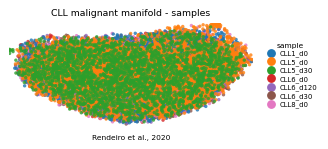

In [12]:
# House style (figsize=(3.5,1.5) horizontal strip, size=30) to match every other panel.
# Colour = sample: intermixing across the strip is the Gate-1 batch-integration evidence,
# shown on the house orientation (X_umap_lin) so this panel shares one orientation with 02/03/04.
plot = adata.copy(); plot.obsm['X_umap'] = plot.obsm['X_umap_lin']
xl = plot.obsm['X_umap']
xlo, xhi = np.percentile(xl[:,0], [0.3, 99.7]); ylo, yhi = np.percentile(xl[:,1], [0.3, 99.7])
px = (xhi-xlo)*.05; py = (yhi-ylo)*.08
fig, ax = plt.subplots(figsize=(3.5,1.5))
sc.pl.umap(plot, color='sample', size=30, alpha=.8, frameon=False, show=False, ax=ax)
h, l = ax.get_legend_handles_labels()
ax.legend(h, l, ncol=1, frameon=False, loc='center left', bbox_to_anchor=(1.02, .5),
          handletextpad=.2, labelspacing=.25, fontsize=5.5, title='sample', title_fontsize=6)
ax.set_xlim(xlo-px, xhi+px); ax.set_ylim(ylo-py, yhi+py)
ax.set_title('CLL malignant manifold - samples', size=7.5)
ax.text(.5, -.12, 'Rendeiro et al., 2020', ha='center', transform=ax.transAxes, size=6)
fig.savefig(os.path.join(pth_fig,'samples.pdf'), bbox_inches='tight')
print('saved samples.pdf | cells:', plot.shape[0])